# Getting Started

## Loading and Shaping the Iris Dataset

In [89]:
from sklearn.datasets import load_iris
import numpy as np

iris_load = load_iris(return_X_y=True, as_frame=True)
data = iris_load[0]
labels = iris_load[1]

# data has column name information that we're about to lose when we convert it to a numpy array, so let's print the column names first
# Print the column names of data
print("Column names of data before conversion to numpy array:")
print("data.columns.tolist():", data.columns.tolist())

data = data.to_numpy()

# labels is a list of integers, we need to reshape it to a 1D array before concatenating with data
labels = np.reshape(labels,(150,1))

# Print the shape of labels after reshaping
print("Labels shape after reshaping:")
print(f"labels.shape: {labels.shape}")

# Print the shape of data
print("Shape of data before concatenation:", data.shape)
print("data.shape:", data.shape)

# Concatenate data and labels along the last axis
concatenated_data = np.concatenate(
    (data, labels),
    axis=1
)

# Print the shape of concatenated_data after concatenation
print("Shape of concatenated_data after concatenation:")
print(f"concatenated_data.shape: {concatenated_data.shape}")


Column names of data before conversion to numpy array:
data.columns.tolist(): ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Labels shape after reshaping:
labels.shape: (150, 1)
Shape of data before concatenation: (150, 4)
data.shape: (150, 4)
Shape of concatenated_data after concatenation:
concatenated_data.shape: (150, 5)


## Some Useful Constants

In [90]:
from matplotlib.pylab import Enum

class DATASET_COLUMN_NAME(Enum):
    SEPAL_LENGTH = 'sepal-length'
    SEPAL_WIDTH = 'sepal-width'
    PETAL_LENGTH = 'petal-length'
    PETAL_WIDTH = 'petal-width'
    SPECIES = 'species'

DATASET_COLUMN_NAMES = []
for i in DATASET_COLUMN_NAME:
    DATASET_COLUMN_NAMES.append(i.value)

DATASET_COLUMN_NUMBERS = {
    DATASET_COLUMN_NAME.SEPAL_LENGTH: 0,
    DATASET_COLUMN_NAME.SEPAL_WIDTH: 1,
    DATASET_COLUMN_NAME.PETAL_LENGTH: 2,
    DATASET_COLUMN_NAME.PETAL_WIDTH: 3,
    DATASET_COLUMN_NAME.SPECIES: 4
}

class SPECIES_NAME(Enum):
    IRIS_SETOSA = "Iris-setosa"
    IRIS_VERSICOLOR = "Iris-versicolor"
    IRIS_VIRGINICA = "Iris-virginica"

SPECIES_NAMES = []
for i in SPECIES_NAME:
    SPECIES_NAMES.append(i.value)    

## Formatting the Dataset into a Pandas DataFrame

In [91]:
import pandas as pd

dataset = pd.DataFrame(concatenated_data,columns=DATASET_COLUMN_NAMES)

# Print the shape of the dataset
print("Dataset shape after conversion to DataFrame:")
print(f"dataset.shape: {dataset.shape}")

# Print the info for the dataset to check the data types of each column
print("Dataset info:")
print(f"{dataset.info()}")

Dataset shape after conversion to DataFrame:
dataset.shape: (150, 5)
Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal-length  150 non-null    float64
 1   sepal-width   150 non-null    float64
 2   petal-length  150 non-null    float64
 3   petal-width   150 non-null    float64
 4   species       150 non-null    float64
dtypes: float64(5)
memory usage: 6.0 KB
None


## Give Meaningful Values to Entries in the Species Column

In [92]:
species_column = DATASET_COLUMN_NAME.SPECIES.value

# Print the unique values in the species column before replacement
print("Unique values in the species column before replacement:")
print(f"dataset[species_column].unique(): {dataset[species_column].unique()}")

for i in range(SPECIES_NAMES.__len__()):
    my_species = SPECIES_NAMES[i]
    dataset[species_column]=dataset[species_column].replace(float(i), my_species,inplace=False)

# Print the unique values in the species column after replacement
print("Unique values in the species column after replacement:")
print(f"dataset[species_column].unique(): {dataset[species_column].unique()}")

Unique values in the species column before replacement:
dataset[species_column].unique(): [0. 1. 2.]
Unique values in the species column after replacement:
dataset[species_column].unique(): ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


## Some Simple Plots as an Appetizer

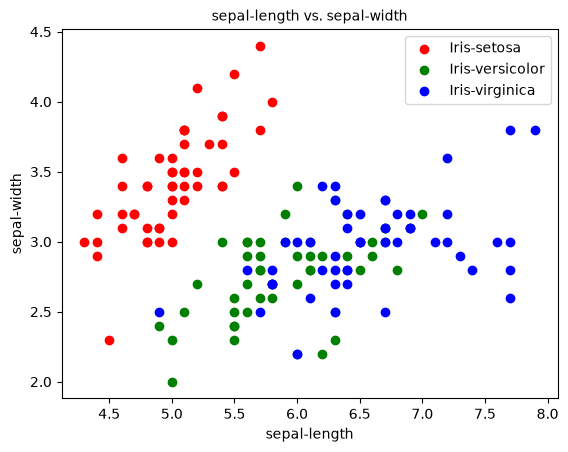

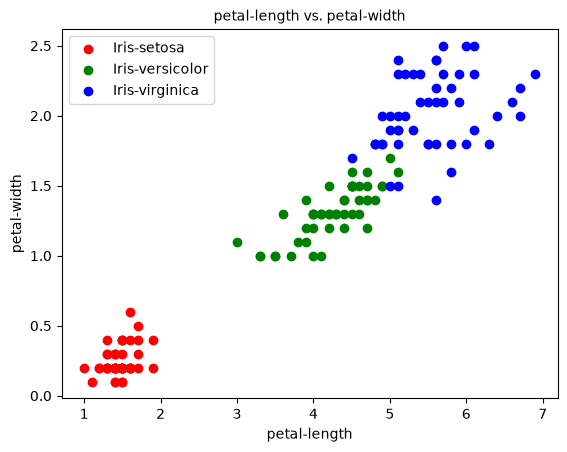

In [93]:
import matplotlib.pyplot as plt

def iris_scatter_plot(dataset: pd.DataFrame, scatter_axes: list[DATASET_COLUMN_NAME]) -> None:
    xaxis = scatter_axes[0].value
    yaxis = scatter_axes[1].value
    x_col_idx = dataset.columns.get_loc(xaxis)
    y_col_idx = dataset.columns.get_loc(yaxis)
    title = xaxis + " vs. " + yaxis
    colors = ['r', 'g', 'b']
    color_idx = 0
    species_grouped_dataset = dataset.groupby(DATASET_COLUMN_NAME.SPECIES.value)
    for species in species_grouped_dataset.groups:
        curr_data = np.array(species_grouped_dataset.get_group(species).values)
        plt.scatter(curr_data[:, x_col_idx], 
                    curr_data[:, y_col_idx], 
                    c=colors[color_idx], label=species)
        color_idx = (color_idx + 1) % len(colors)

    plt.xlabel(xaxis,fontsize=10)
    plt.ylabel(yaxis,fontsize=10)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.title(title,fontsize=10)
    plt.legend(prop={'size': 10})
    plt.show()

iris_scatter_plot(dataset, [DATASET_COLUMN_NAME.SEPAL_LENGTH, DATASET_COLUMN_NAME.SEPAL_WIDTH])
iris_scatter_plot(dataset, [DATASET_COLUMN_NAME.PETAL_LENGTH, DATASET_COLUMN_NAME.PETAL_WIDTH])


# Looking for Correlations Between the Variables

## Building a Correlation Matrix

In [94]:
from collections import deque

def build_variable_corr_by_species(dataset: pd.DataFrame) -> dict:
    variable_corr_by_species = {}
    species_grouped_dataset = dataset.groupby(DATASET_COLUMN_NAME.SPECIES.value)
    for species in species_grouped_dataset.groups:
        curr_data = np.array(species_grouped_dataset.get_group(species).values)
        variable_corr_by_species[species] = pd.DataFrame(curr_data[:,0:4],columns=DATASET_COLUMN_NAMES[0:4]).corr()
    return variable_corr_by_species

variable_corr_by_species = build_variable_corr_by_species(dataset)

In [95]:
species_grouped_dataset = dataset.groupby(DATASET_COLUMN_NAME.SPECIES.value)
for species_group in species_grouped_dataset.groups:
    print(f"Correlation for species group: {species_group}")
    print(variable_corr_by_species[species_group])
    print("------------------------------")


Correlation for species group: Iris-setosa
              sepal-length  sepal-width  petal-length  petal-width
sepal-length      1.000000     0.742547      0.267176     0.278098
sepal-width       0.742547     1.000000      0.177700     0.232752
petal-length      0.267176     0.177700      1.000000     0.331630
petal-width       0.278098     0.232752      0.331630     1.000000
------------------------------
Correlation for species group: Iris-versicolor
              sepal-length  sepal-width  petal-length  petal-width
sepal-length      1.000000     0.525911      0.754049     0.546461
sepal-width       0.525911     1.000000      0.560522     0.663999
petal-length      0.754049     0.560522      1.000000     0.786668
petal-width       0.546461     0.663999      0.786668     1.000000
------------------------------
Correlation for species group: Iris-virginica
              sepal-length  sepal-width  petal-length  petal-width
sepal-length      1.000000     0.457228      0.864225     0.28110

### Visualising the Correlation Matrix

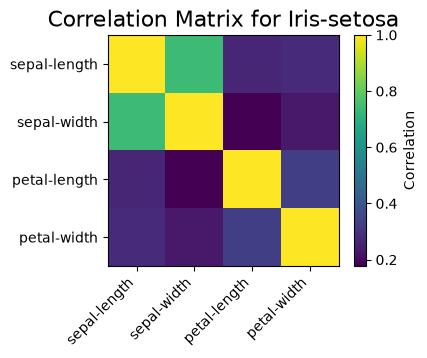

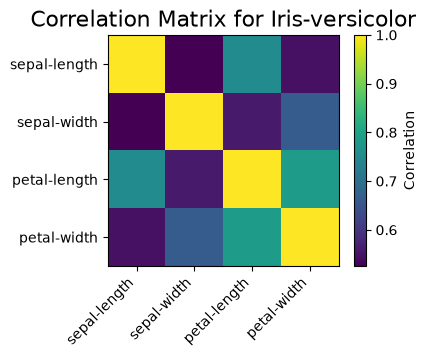

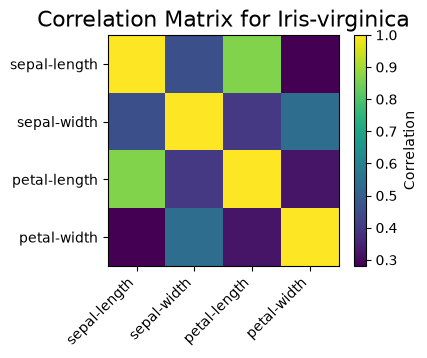

In [96]:
species_grouped_dataset = dataset.groupby('species')
for species in species_grouped_dataset.groups.keys():
    df = variable_corr_by_species[species]
    plt.figure(figsize=(4, 3))
    plt.imshow(df, cmap='viridis')
    plt.colorbar(label='Correlation')  # Shows what the colors mean
    plt.title(f"Correlation Matrix for {species}", fontsize=16)
    plt.xticks(ticks=np.arange(len(df.columns)), labels=deque(df.columns), rotation=45, ha='right')
    plt.yticks(ticks=np.arange(len(df.index)), labels=deque(df.index))
    plt.show()

### Pairwise Variable Visualising

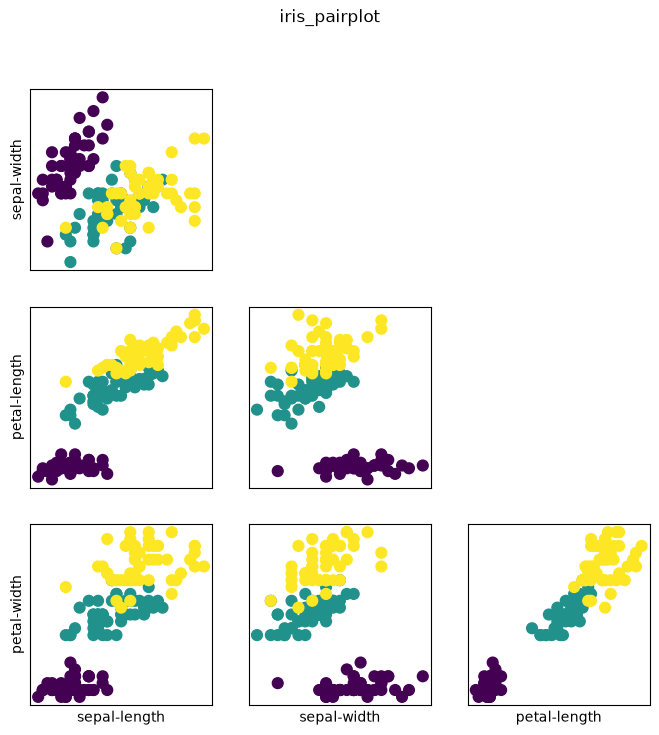

In [97]:
X = data # Sepal and petal measurements
y = labels # Iris species
fig, ax = plt.subplots(3, 3, figsize=(8, 8))
plt.suptitle("iris_pairplot")
for i in range(3):
    for j in range(3):
        ax[i,j].scatter(X[:,j], X[:,i+1], c=y, s=60)
        ax[i,j].set_xticks(())
        ax[i,j].set_yticks(())
        if i == 2:
            ax[i,j].set_xlabel(DATASET_COLUMN_NAMES[j])
        if j == 0:
            ax[i,j].set_ylabel(DATASET_COLUMN_NAMES[i+1])
        if j > i:
            ax[i,j].set_visible(False)

# Gearing Up for Machine Learning

In [98]:
from sklearn.model_selection import train_test_split
train_data, test_data, train_label, test_label = train_test_split(dataset.iloc[:,:4], dataset.iloc[:,4], test_size=0.1, random_state=42) 

# K-Nearest Neighbors

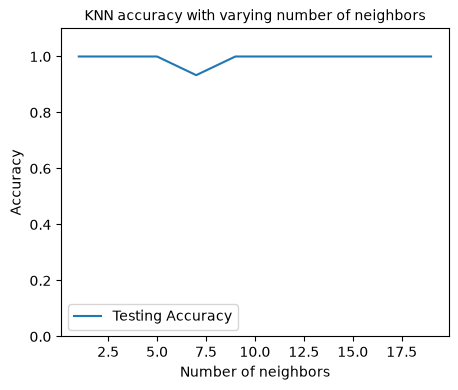

In [99]:
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

neighbors = np.arange(1, 20, 2)
#train_accuracy = np.zeros(len(neighbors))
test_accuracy = np.zeros(len(neighbors))
for i, k in enumerate(neighbors):
    knn = KNeighborsClassifier(n_neighbors=k)

    #Fit the model
    knn.fit(train_data, train_label)

    #Compute accuracy on the training set
    #train_accuracy[i] = knn.score(train_data, train_label)

    #Compute accuracy on the test set
    test_accuracy[i] = knn.score(test_data, test_label)

plt.figure(figsize=(5,4))
plt.title('KNN accuracy with varying number of neighbors',fontsize=10)
plt.plot(neighbors, test_accuracy, label='Testing Accuracy')
#plt.plot(neighbors, train_accuracy, label='Training accuracy')
plt.legend(prop={'size': 10})
plt.xlabel('Number of neighbors',fontsize=10)
plt.ylabel('Accuracy',fontsize=10)
plt.ylim(0, 1.1)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

## Using KNN for Feature Selection

In [100]:
def generate_arrays_of_indices():
    # Generate an array of subsets of variables from the iris dataset
    # Each subset will contain 1 or more variables (columns) from the dataset with no duplicates
    num_variables = dataset.shape[1] - 1  # Exclude the species column
    raw_arrays_of_indices = []
    for i in range(1, num_variables + 1):
        # Generate all combinations of i variables
        indices = np.arange(num_variables)
        combinations = np.array(np.meshgrid(*[indices]*i)).T.reshape(-1, i)
        raw_arrays_of_indices.extend(combinations)
    # Sort the arrays of indices
    sorted_arrays_of_indices = [np.sort(arr) for arr in raw_arrays_of_indices]
    # Remove duplicates
    unique_arrays_of_indices = []
    for arr in sorted_arrays_of_indices:
        if not any(np.array_equal(arr, x) for x in unique_arrays_of_indices):
            unique_arrays_of_indices.append(arr)
    # Remove arrays that have duplicates in the indices
    final_arrays_of_indices = []
    for arr in unique_arrays_of_indices:
        if len(np.unique(arr)) == len(arr):
            final_arrays_of_indices.append(arr)
    return final_arrays_of_indices

generated_arrays_of_indices = generate_arrays_of_indices()

print("Generated arrays of indices:")
for arr in generated_arrays_of_indices:
    print(arr)

Generated arrays of indices:
[0]
[1]
[2]
[3]
[0 1]
[0 2]
[0 3]
[1 2]
[1 3]
[2 3]
[0 1 2]
[0 1 3]
[0 2 3]
[1 2 3]
[0 1 2 3]


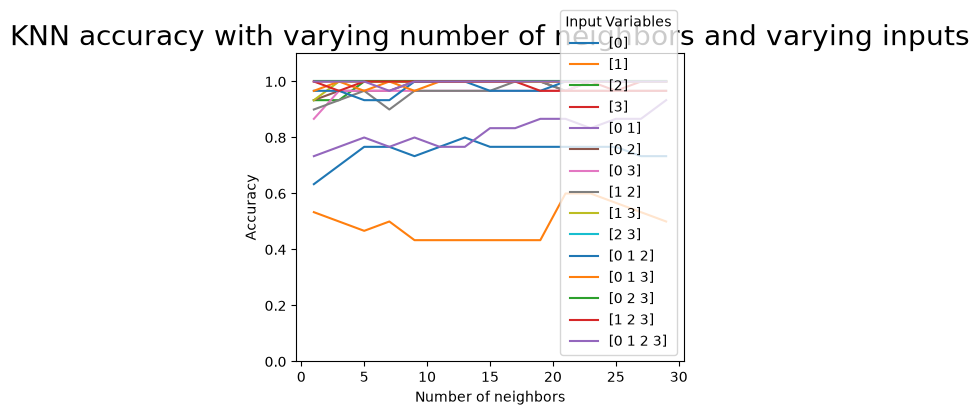

In [101]:
array_of_indices = generate_arrays_of_indices()

test_accuracies = {}
neighbors = 0
for indices in array_of_indices:
    train_data, test_data, train_label, test_label = train_test_split(dataset.iloc[:,indices], dataset.iloc[:,4], test_size=0.2, random_state=42) 

    neighbors = np.arange(1,30,2)
    test_accuracy = np.zeros(len(neighbors))
    for i,k in enumerate(neighbors):
        knn = KNeighborsClassifier(n_neighbors=k)

        #Fit the model
        knn.fit(train_data, train_label)

        #Compute accuracy on the test set
        test_accuracy[i] = knn.score(test_data, test_label)
    test_accuracies[str(indices)] = test_accuracy

plt.figure(figsize=(5,4))
plt.title('KNN accuracy with varying number of neighbors and varying inputs',fontsize=20)

for x in test_accuracies.keys():
    test_accuracy = test_accuracies[x]
    plt.plot(neighbors, test_accuracy, label=x)  # Random color for each line

plt.legend(prop={'size': 10}, title='Input Variables', title_fontsize=10, loc='lower right')
plt.xlabel('Number of neighbors',fontsize=10)
plt.ylabel('Accuracy',fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.ylim(0, 1.1)
plt.show()  

# Gaussian Naive-Bayes

Plotting features: sepal-length (index 0) vs sepal-width (index 1)


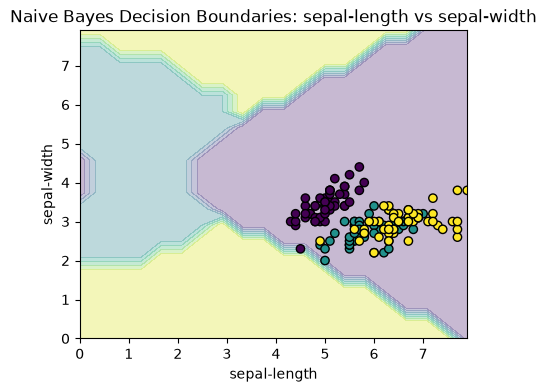

Plotting features: sepal-length (index 0) vs petal-length (index 2)


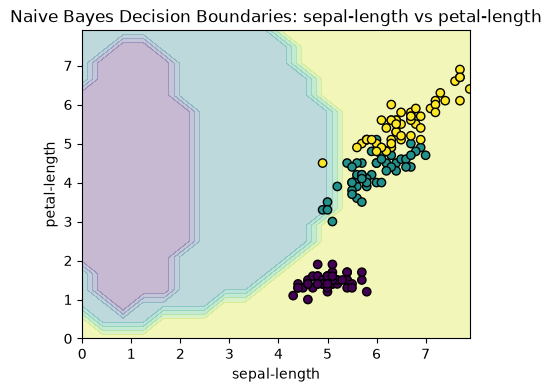

Plotting features: sepal-length (index 0) vs petal-width (index 3)


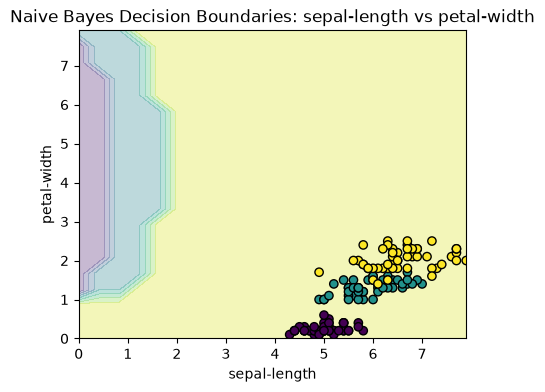

Plotting features: sepal-width (index 1) vs petal-length (index 2)


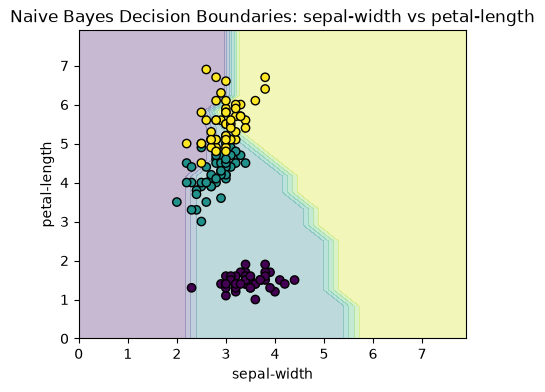

Plotting features: sepal-width (index 1) vs petal-width (index 3)


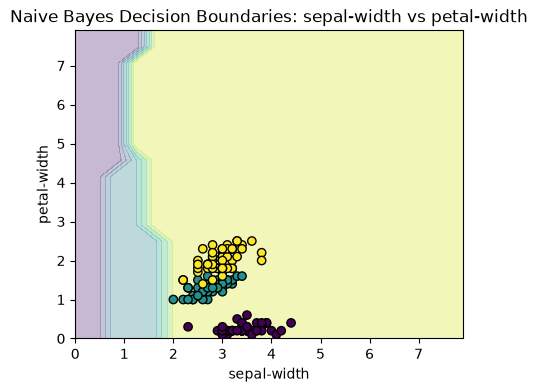

Plotting features: petal-length (index 2) vs petal-width (index 3)


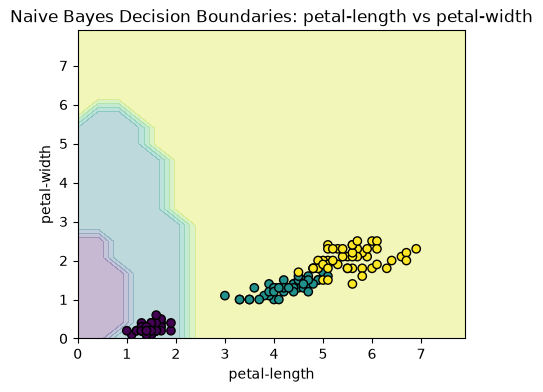

In [102]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
X = data
y = labels.ravel()  # Flatten the labels array to 1D

nb.fit(X, y)

lengths = np.linspace(min(0, X.min()), X.max(), num=20)

# Create a grid of points for the first two features (sepal length and sepal width)
grid_points = np.array(np.meshgrid(lengths, lengths)).T.reshape(-1, 2)

# Predict the species for each point in the grid
nb_2d = GaussianNB()
for i in range(3):
    for j in range(4):
        if i < j:
            # Fit the model using only the two selected features
            nb_2d.fit(X[:, [i, j]], y)

            # Predict the species for each point in the grid
            grid_predictions = nb_2d.predict(grid_points)

            # Reshape the predictions to match the grid shape
            grid_predictions = grid_predictions.reshape(len(lengths), len(lengths))

            # Plotting the decision boundaries
            plt.figure(figsize=(5, 4))
            # Create a contour plot for the decision boundaries
            plt.contourf(lengths, lengths, grid_predictions, alpha=0.3, cmap='viridis')
            # Scatter plot of the original data points
            plt.scatter(X[:, i], X[:, j], c=y, edgecolor='k', cmap='viridis')
            plt.xlabel(DATASET_COLUMN_NAMES[i])
            plt.ylabel(DATASET_COLUMN_NAMES[j])
            plt.title(f'Naive Bayes Decision Boundaries: {DATASET_COLUMN_NAMES[i]} vs {DATASET_COLUMN_NAMES[j]}')
            # Print i and j to identify which features are being plotted
            print(f'Plotting features: {DATASET_COLUMN_NAMES[i]} (index {i}) vs {DATASET_COLUMN_NAMES[j]} (index {j})')
            plt.show()
